# Module: Machine Learning Fundamentals — Regression, Loss Models, Validation & Regularization

- **High-Level Overview**: What machine learning actually does under the hood — finding generalizable relationships between features and target outcomes without hardcoding explicit rules.
- **Linear Regression**: Constructing our predictive baseline, interpreting weights as directional sensitivities, and visualizing fitted regression lines against raw data.
- **Loss Models & Metrics**: Quantifying prediction errors using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and $R^2$; visualizing the error surface ("loss bowl").
- **Train / Validation / Test Splits**: Why in-sample accuracy is deceitful, how to structure clean 3-way dataset splits, and how to detect underfitting vs. overfitting.
- **Feature Subsampling & Complexity Inflation**: Simulating the effect of throwing high-dimensional, noisy features into standard linear regression and observing out-of-sample degradation.
- **Regularization ($L_1$ and $L_2$) & Hyperparameter Tuning**: Introducing Ridge ($L_2$) and Lasso ($L_1$) penalties to constrain weights, tuning $\lambda$ (`alpha`) on validation data, and comparing out-of-sample results against plain OLS.

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

### 1. Linear Regression: The Fundamental Predictive Baseline

- At a high level, **supervised machine learning** takes input features ($X$) and learns an empirical function to predict an outcome target ($y$):
  $$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_p x_p + b$$
- **Key Terms**:
  - $\hat{y}$ (Prediction): The model's estimated outcome.
  - $w$ (Weights / Coefficients): Multipliers representing how strongly each feature drives the prediction.
  - $b$ (Bias / Intercept): The baseline predicted value when all input features equal zero.
  - $e = y - \hat{y}$ (Residual / Error): The difference between what actually happened and what the model guessed.
- Below, we generate a synthetic continuous signal with realistic noise to observe how Ordinary Least Squares (OLS) finds the optimal fitting line.

Fitted Slope (Weight w): 2.5483 (True: 2.50)
Fitted Intercept (b):     4.5883 (True: 5.00)


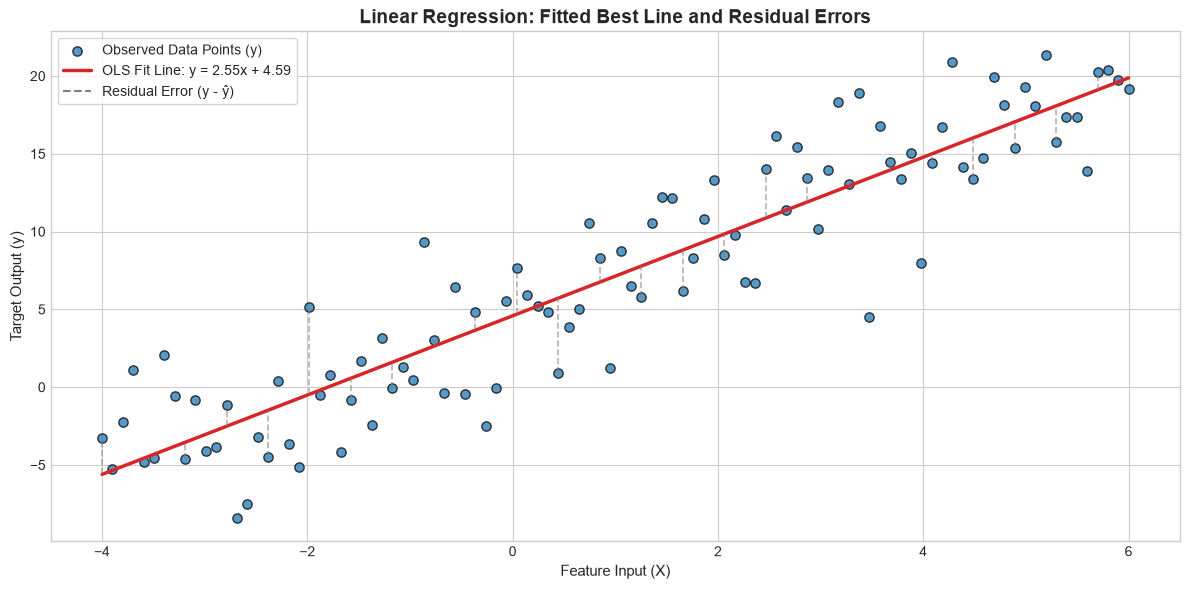

In [37]:
np.random.seed(42)

n_samples = 100
x_raw = np.linspace(-4, 6, n_samples)
noise = np.random.normal(loc=0, scale=3.5, size=n_samples)
y_raw = 2.5 * x_raw + 5.0 + noise

X_simple = x_raw.reshape(-1, 1)
y_simple = y_raw

#IMPORTANT
lin_reg = LinearRegression()
#IMPORTANT
lin_reg.fit(X_simple, y_simple)

#IMPORTANT
y_pred_simple = lin_reg.predict(X_simple)

print(f"Fitted Slope (Weight w): {lin_reg.coef_[0]:.4f} (True: 2.50)")
print(f"Fitted Intercept (b):     {lin_reg.intercept_:.4f} (True: 5.00)")

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(x_raw, y_raw, color='#1f77b4', alpha=0.75, edgecolors='k', s=45, label='Observed Data Points (y)')
ax.plot(x_raw, y_pred_simple, color='#d62728', lw=2.5, label=f'OLS Fit Line: y = {lin_reg.coef_[0]:.2f}x + {lin_reg.intercept_:.2f}')

for i in range(0, n_samples, 4):
    ax.vlines(x=x_raw[i], ymin=min(y_raw[i], y_pred_simple[i]), ymax=max(y_raw[i], y_pred_simple[i]), 
              color='gray', linestyle='--', alpha=0.6, lw=1.2)
ax.plot([], [], color='gray', linestyle='--', label='Residual Error (y - ŷ)')

ax.set_title('Linear Regression: Fitted Best Line and Residual Errors', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Input (X)', fontsize=11)
ax.set_ylabel('Target Output (y)', fontsize=11)
ax.legend(frameon=True, loc='upper left')
plt.tight_layout()
plt.show()

### 2. Loss Models: Quantifying "How Good Is Our Model?"

A **loss function** measures the cost of a model's errors. When we train a model, the algorithm automatically adjusts parameters ($w, b$) to minimize this loss.

- **Mean Squared Error (MSE)**:
  $$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
  - Squares errors, penalizing large mistakes disproportionately.

- **Root Mean Squared Error (RMSE)**:
  $$\text{RMSE} = \sqrt{\text{MSE}}$$
  - Expresses error magnitude in the exact same physical units as the target $y$.

- **Mean Absolute Error (MAE)**:
  $$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
  - Linear error penalty; much more robust against extreme outliers than MSE.

- **Coefficient of Determination ($R^2$ Score)**:
  $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
  - Proportion of total variance in $y$ explained by the features ($1.0$ = perfect fit, $0.0$ = identical to guessing the mean).

Model Performance Summary:
 - Mean Squared Error (MSE):  9.9826
 - Root Mean Squared (RMSE):  3.1595
 - Mean Absolute Error (MAE): 2.5024
 - R² Score (Goodness of Fit):0.8469


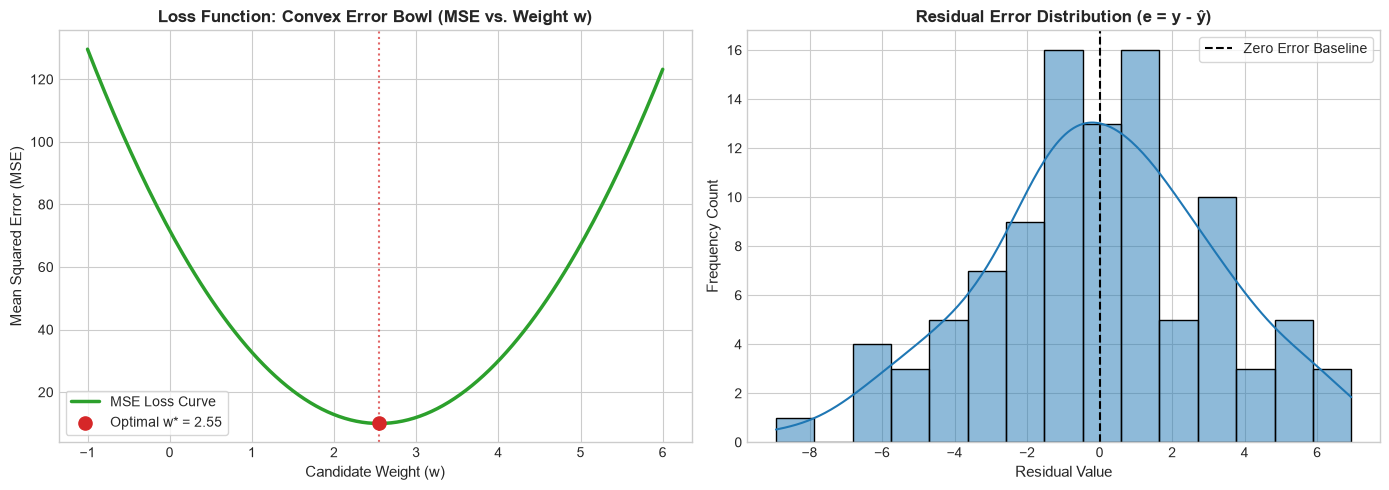

In [38]:
#IMPORTANT
mse = mean_squared_error(y_simple, y_pred_simple)
#IMPORTANT
rmse = np.sqrt(mse)
#IMPORTANT
mae = mean_absolute_error(y_simple, y_pred_simple)
#IMPORTANT
r2 = r2_score(y_simple, y_pred_simple)

print(f"Model Performance Summary:")
print(f" - Mean Squared Error (MSE):  {mse:.4f}")
print(f" - Root Mean Squared (RMSE):  {rmse:.4f}")
print(f" - Mean Absolute Error (MAE): {mae:.4f}")
print(f" - R² Score (Goodness of Fit):{r2:.4f}")

candidate_weights = np.linspace(-1.0, 6.0, 200)
weight_losses = []

for w in candidate_weights:
    y_candidate = w * x_raw + lin_reg.intercept_
    weight_losses.append(mean_squared_error(y_simple, y_candidate))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(candidate_weights, weight_losses, color='#2ca02c', lw=2.5, label='MSE Loss Curve')
ax1.scatter([lin_reg.coef_[0]], [mse], color='#d62728', s=90, zorder=5, label=f'Optimal w* = {lin_reg.coef_[0]:.2f}')
ax1.axvline(lin_reg.coef_[0], color='#d62728', linestyle=':', alpha=0.7)
ax1.set_title('Loss Function: Convex Error Bowl (MSE vs. Weight w)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Candidate Weight (w)', fontsize=11)
ax1.set_ylabel('Mean Squared Error (MSE)', fontsize=11)
ax1.legend(frameon=True)

residuals = y_simple - y_pred_simple
sns.histplot(residuals, kde=True, color='#1f77b4', ax=ax2, bins=15)
ax2.axvline(0, color='black', linestyle='--', lw=1.5, label='Zero Error Baseline')
ax2.set_title('Residual Error Distribution (e = y - ŷ)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Residual Value', fontsize=11)
ax2.set_ylabel('Frequency Count', fontsize=11)
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

### 3. Generalization: Train, Validation, and Test Splits

- **The In-Sample Trap**: If we test our model on the exact same data used to train it, we measure **memorization**, not **generalization**.
- To guarantee unbiased real-world performance, we partition our data into three isolated partitions:
  1. **Train Set (~70%)**: The algorithm learns the coefficients ($w, b$) exclusively from this subset.
  2. **Validation Set (~15%)**: Used to compare different models and tune hyperparameters (e.g., penalty strength $\lambda$).
  3. **Test Set (~15%)**: Kept in a vault until modeling is finished. Provides the final unbiased report card.

Dataset Partition Counts:
 - Train set:      210 samples (70%)
 - Validation set: 45 samples (15%)
 - Test set:       45 samples (15%)


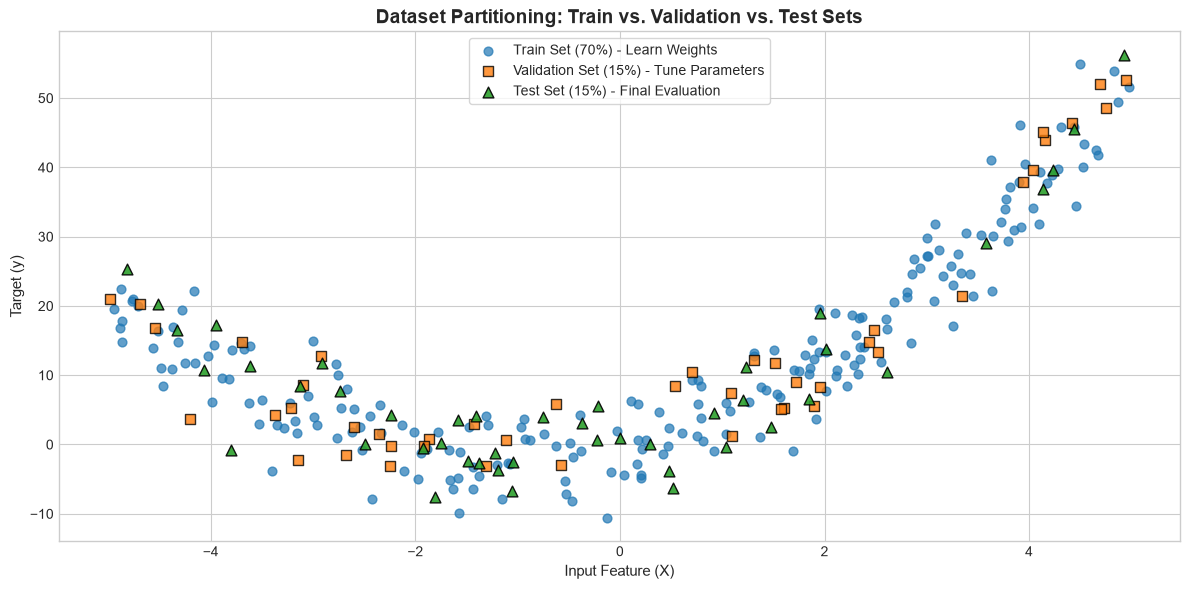

In [39]:
np.random.seed(101)
N = 300
X_full = np.random.uniform(-5, 5, size=(N, 1))
y_full = 3.0 * X_full.ravel() + 1.5 * (X_full.ravel() ** 2) + np.random.normal(0, 4.0, size=N)

#IMPORTANT
X_train, X_temp, y_train, y_temp = train_test_split(X_full, y_full, test_size=0.30, random_state=42)

#IMPORTANT
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f"Dataset Partition Counts:")
print(f" - Train set:      {len(X_train)} samples ({len(X_train)/N*100:.0f}%)")
print(f" - Validation set: {len(X_val)} samples ({len(X_val)/N*100:.0f}%)")
print(f" - Test set:       {len(X_test)} samples ({len(X_test)/N*100:.0f}%)")

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(X_train, y_train, color='#1f77b4', alpha=0.7, s=40, label='Train Set (70%) - Learn Weights')
ax.scatter(X_val, y_val, color='#ff7f0e', alpha=0.8, s=55, marker='s', edgecolors='k', label='Validation Set (15%) - Tune Parameters')
ax.scatter(X_test, y_test, color='#2ca02c', alpha=0.9, s=60, marker='^', edgecolors='k', label='Test Set (15%) - Final Evaluation')

ax.set_title('Dataset Partitioning: Train vs. Validation vs. Test Sets', fontsize=14, fontweight='bold')
ax.set_xlabel('Input Feature (X)', fontsize=11)
ax.set_ylabel('Target (y)', fontsize=11)
ax.legend(frameon=True, loc='upper center')
plt.tight_layout()
plt.show()

### 4. Feature Subsampling & Complexity Inflation

- What happens when we feed an ordinary linear regression model dozens of features, many of which are purely random uninformative noise?
- As the number of features increases:
  - **Training Loss** almost always continues to drop because OLS can exploit random noise to fit every quirk of the training data.
  - **Test Loss** starts exploding when the model becomes over-parameterized (variance explosion).
- Below, we simulate 60 candidate features (where only 5 contain real signal, and 55 are random Gaussian noise) and sample subsets of increasing size.

#### What the Data Looks Like

- Each row is one observation; each of the 60 columns ($x_1, \dots, x_{60}$) is a feature.
- **$x_1$ – $x_5$ (colored)** actually drive the target: $y = 4.5x_1 - 3.2x_2 + 2.8x_3 - 2.0x_4 + 3.5x_5 + \text{noise}$
- **$x_6$ – $x_{60}$ (grey)** are random numbers with zero real connection to $y$.
- In the experiment below, features are added **in order**: $k = 5$ uses exactly the 5 real features, and every feature after that is pure noise the model can only use to memorize the training set.

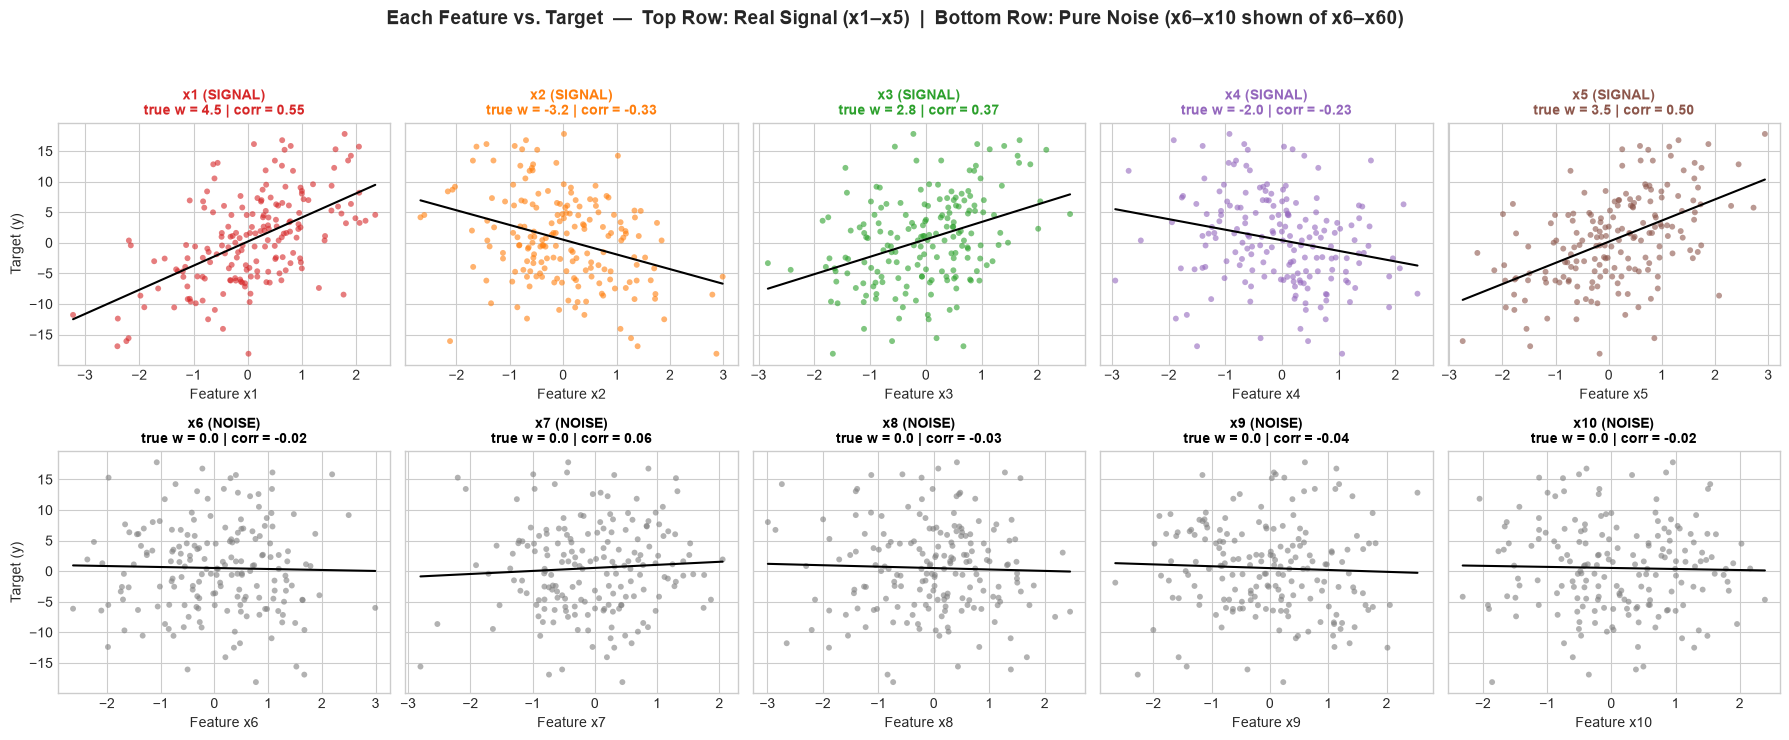

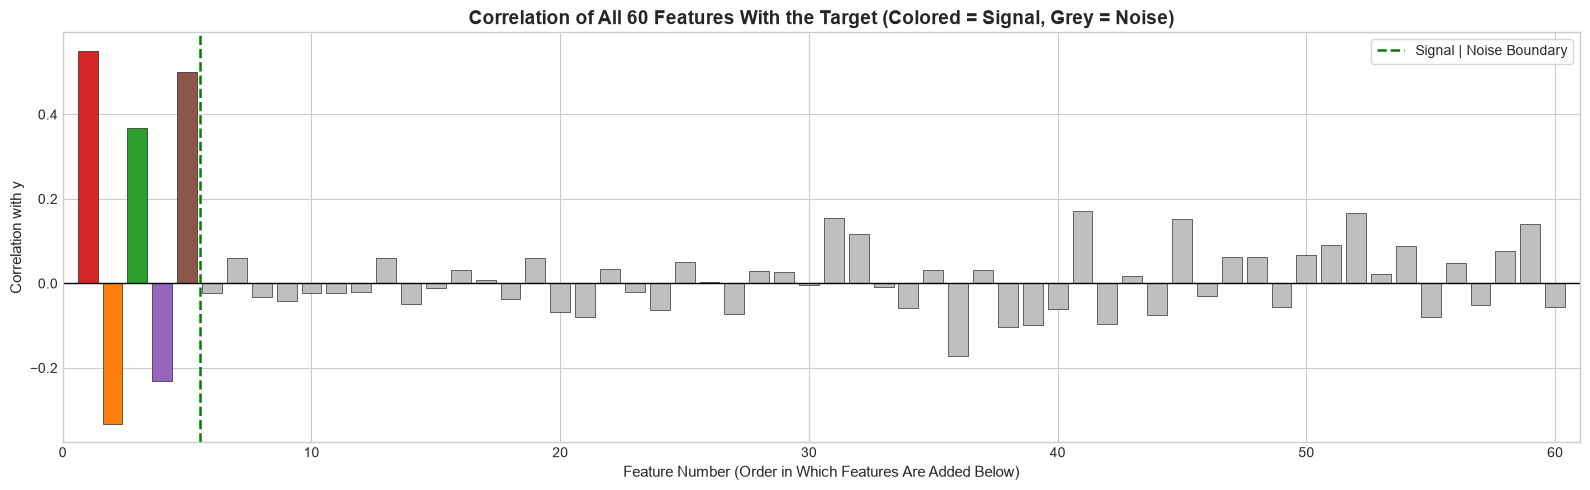

In [40]:
np.random.seed(42)
n_obs = 180
n_total_features = 60

#IMPORTANT
X_all = np.random.normal(0, 1, size=(n_obs, n_total_features))

true_weights = np.zeros(n_total_features)
true_weights[:5] = [4.5, -3.2, 2.8, -2.0, 3.5]
#IMPORTANT
y_multi = np.dot(X_all, true_weights) + np.random.normal(0, 2.0, size=n_obs)

signal_colors = ['#d62728', '#ff7f0e', '#2ca02c', '#9467bd', '#8c564b']

fig, axes = plt.subplots(2, 5, figsize=(18, 7.5), sharey=True)
for ax, j in zip(axes.ravel(), range(10)):
    is_signal = j < 5
    color = signal_colors[j] if is_signal else '#7f7f7f'
    ax.scatter(X_all[:, j], y_multi, color=color, alpha=0.6, s=18, edgecolors='none')
    slope, intercept = np.polyfit(X_all[:, j], y_multi, 1)
    xs = np.linspace(X_all[:, j].min(), X_all[:, j].max(), 50)
    ax.plot(xs, slope * xs + intercept, color='black', lw=1.5)
    corr = np.corrcoef(X_all[:, j], y_multi)[0, 1]
    label = 'SIGNAL' if is_signal else 'NOISE'
    ax.set_title(f'x{j+1} ({label})\ntrue w = {true_weights[j]:.1f} | corr = {corr:.2f}', fontsize=10, fontweight='bold', color=color if is_signal else 'black')
    ax.set_xlabel(f'Feature x{j+1}')
axes[0, 0].set_ylabel('Target (y)')
axes[1, 0].set_ylabel('Target (y)')
fig.suptitle('Each Feature vs. Target  —  Top Row: Real Signal (x1–x5)  |  Bottom Row: Pure Noise (x6–x10 shown of x6–x60)', fontsize=14, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

correlations = [np.corrcoef(X_all[:, j], y_multi)[0, 1] for j in range(n_total_features)]
bar_colors = [signal_colors[j] if j < 5 else '#bfbfbf' for j in range(n_total_features)]

fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(range(1, n_total_features + 1), correlations, color=bar_colors, edgecolor='k', linewidth=0.4)
ax.axhline(0, color='black', lw=1)
ax.axvline(5.5, color='green', linestyle='--', lw=1.8, label='Signal | Noise Boundary')
ax.set_title('Correlation of All 60 Features With the Target (Colored = Signal, Grey = Noise)', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Number (Order in Which Features Are Added Below)', fontsize=11)
ax.set_ylabel('Correlation with y', fontsize=11)
ax.set_xlim(0, n_total_features + 1)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

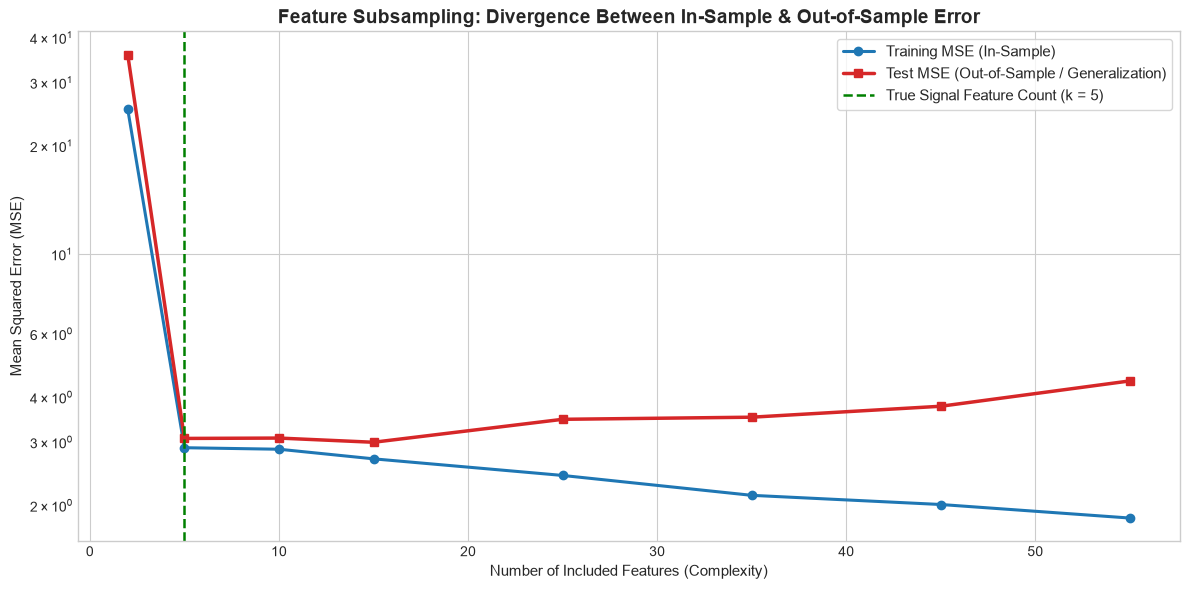

In [41]:
#IMPORTANT
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_multi, test_size=0.35, random_state=42)

feature_counts = [2, 5, 10, 15, 25, 35, 45, 55]
train_errors = []
test_errors = []

for k in feature_counts:
    #IMPORTANT
    X_tr_sub = X_tr[:, :k]
    #IMPORTANT
    X_te_sub = X_te[:, :k]
    
    #IMPORTANT
    model_k = LinearRegression().fit(X_tr_sub, y_tr)
    
    #IMPORTANT
    train_errors.append(mean_squared_error(y_tr, model_k.predict(X_tr_sub)))
    #IMPORTANT
    test_errors.append(mean_squared_error(y_te, model_k.predict(X_te_sub)))

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(feature_counts, train_errors, marker='o', lw=2.2, color='#1f77b4', label='Training MSE (In-Sample)')
ax.plot(feature_counts, test_errors, marker='s', lw=2.5, color='#d62728', label='Test MSE (Out-of-Sample / Generalization)')
ax.axvline(5, color='green', linestyle='--', lw=1.8, label='True Signal Feature Count (k = 5)')

ax.set_title('Feature Subsampling: Divergence Between In-Sample & Out-of-Sample Error', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Included Features (Complexity)', fontsize=11)
ax.set_ylabel('Mean Squared Error (MSE)', fontsize=11)
ax.set_yscale('log')
ax.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.show()

### 5. Parameter Tuning: Regularization ($L_1$ and $L_2$)

When models have many features, standard regression overfits because its weights can grow arbitrarily large. **Regularization** adds a penalty term for large weights directly into the loss function:

- **Ridge Regression ($L_2$ Regularization)**:
  $$\text{Total Loss} = \text{MSE} + \lambda \sum_{j=1}^{p} w_j^2$$

- **Lasso Regression ($L_1$ Regularization)**:
  $$\text{Total Loss} = \text{MSE} + \lambda \sum_{j=1}^{p} |w_j|$$

- **The Regularization Strength Parameter $\lambda$ (`alpha` in scikit-learn)**:
  - $\lambda \to 0$: Reverts to standard unpenalized OLS (high variance, risk of overfitting).
  - $\lambda \to \infty$: Heavy penalty squashing all weights toward zero (high bias, risk of underfitting).
  - **Optimal $\lambda^*$**: Discovered through parameter tuning on our validation set.

In [42]:
X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=0.25, random_state=42)

scaler = StandardScaler()
#IMPORTANT
X_fit_s = scaler.fit_transform(X_fit)
#IMPORTANT
X_val_s = scaler.transform(X_val)
#IMPORTANT
X_te_s = scaler.transform(X_te)

alphas = np.logspace(-3, 2, 50)
ridge_val_mse = []
lasso_val_mse = []

for a in alphas:
    #IMPORTANT
    ridge_val_mse.append(mean_squared_error(y_val, Ridge(alpha=a).fit(X_fit_s, y_fit).predict(X_val_s)))
    #IMPORTANT
    lasso_val_mse.append(mean_squared_error(y_val, Lasso(alpha=a, max_iter=10000).fit(X_fit_s, y_fit).predict(X_val_s)))

#IMPORTANT
best_ridge_alpha = alphas[np.argmin(ridge_val_mse)]
#IMPORTANT
best_lasso_alpha = alphas[np.argmin(lasso_val_mse)]

models = {
    'OLS (No Regularization)': LinearRegression(),
    f'Ridge (L2), λ = {best_ridge_alpha:.3f}': Ridge(alpha=best_ridge_alpha),
    f'Lasso (L1), λ = {best_lasso_alpha:.3f}': Lasso(alpha=best_lasso_alpha, max_iter=10000),
}

rows = []
for name, model in models.items():
    #IMPORTANT
    model.fit(X_fit_s, y_fit)
    #IMPORTANT
    y_oos = model.predict(X_te_s)
    rows.append({
        'Model': name,
        'OOS MSE': mean_squared_error(y_te, y_oos),
        'OOS RMSE': np.sqrt(mean_squared_error(y_te, y_oos)),
        'OOS MAE': mean_absolute_error(y_te, y_oos),
        'OOS R²': r2_score(y_te, y_oos),
        'Non-Zero Weights': int(np.sum(np.abs(model.coef_) > 1e-6)),
    })

oos_results = pd.DataFrame(rows).set_index('Model').round(3)
oos_results

,OOS MSE,OOS RMSE,OOS MAE,OOS R²,Non-Zero Weights
Model,,,,,
OLS (No Regularization),10.037,3.168,2.477,0.814,60
"Ridge (L2), λ = 1.456",9.194,3.032,2.355,0.830,60
"Lasso (L1), λ = 0.222",4.060,2.015,1.654,0.925,17


###Cheat sheet

| Concept | Key Question / Purpose | Formula / Rule of Thumb | When to Use |
| :--- | :--- | :--- | :--- |
| **Linear Regression** | How does target $y$ scale with features $X$? | $\hat{y} = w_1 x_1 + \dots + w_p x_p + b$ | Baseline continuous modeling & interpretable relationships |
| **MSE / RMSE** | How large are our prediction mistakes? | $\text{MSE} = \frac{1}{n} \sum (y - \hat{y})^2$ | When large errors should be heavily penalized |
| **MAE** | What is the average absolute miss? | $\text{MAE} = \frac{1}{n} \sum \|y - \hat{y}\|$ | When data has fat-tailed noise or extreme outliers |
| **Train/Val/Test** | Typical ML split | 70% Train, 15% Val, 15% Test | Always; never evaluate a model on training data |
| **Ridge ($L_2$)** | How do we tame correlated/dense features? | $\text{Loss} = \text{MSE} + \lambda \sum w_j^2$ | When most features have small but real predictive value |
| **Lasso ($L_1$)** | Which features actually matter? | $\text{Loss} = \text{MSE} + \lambda \sum \|w_j\|$ | When you suspect true sparsity (many uninformative features) |